# DABI: Projektaufgabe 2

Gruppe: Sven van Tongeren, Patrick Heß, Sebastian Straßner, Daniel Daub

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Laden des Datensatzes und erste Betrachtungen

,value
date,
1939-01-01,3.3336
1939-02-01,3.3591
1939-03-01,3.4354
1939-04-01,3.4608
1939-05-01,3.4608
...,...
2025-11-01,101.4705
2025-12-01,121.2860
2026-01-01,130.3652


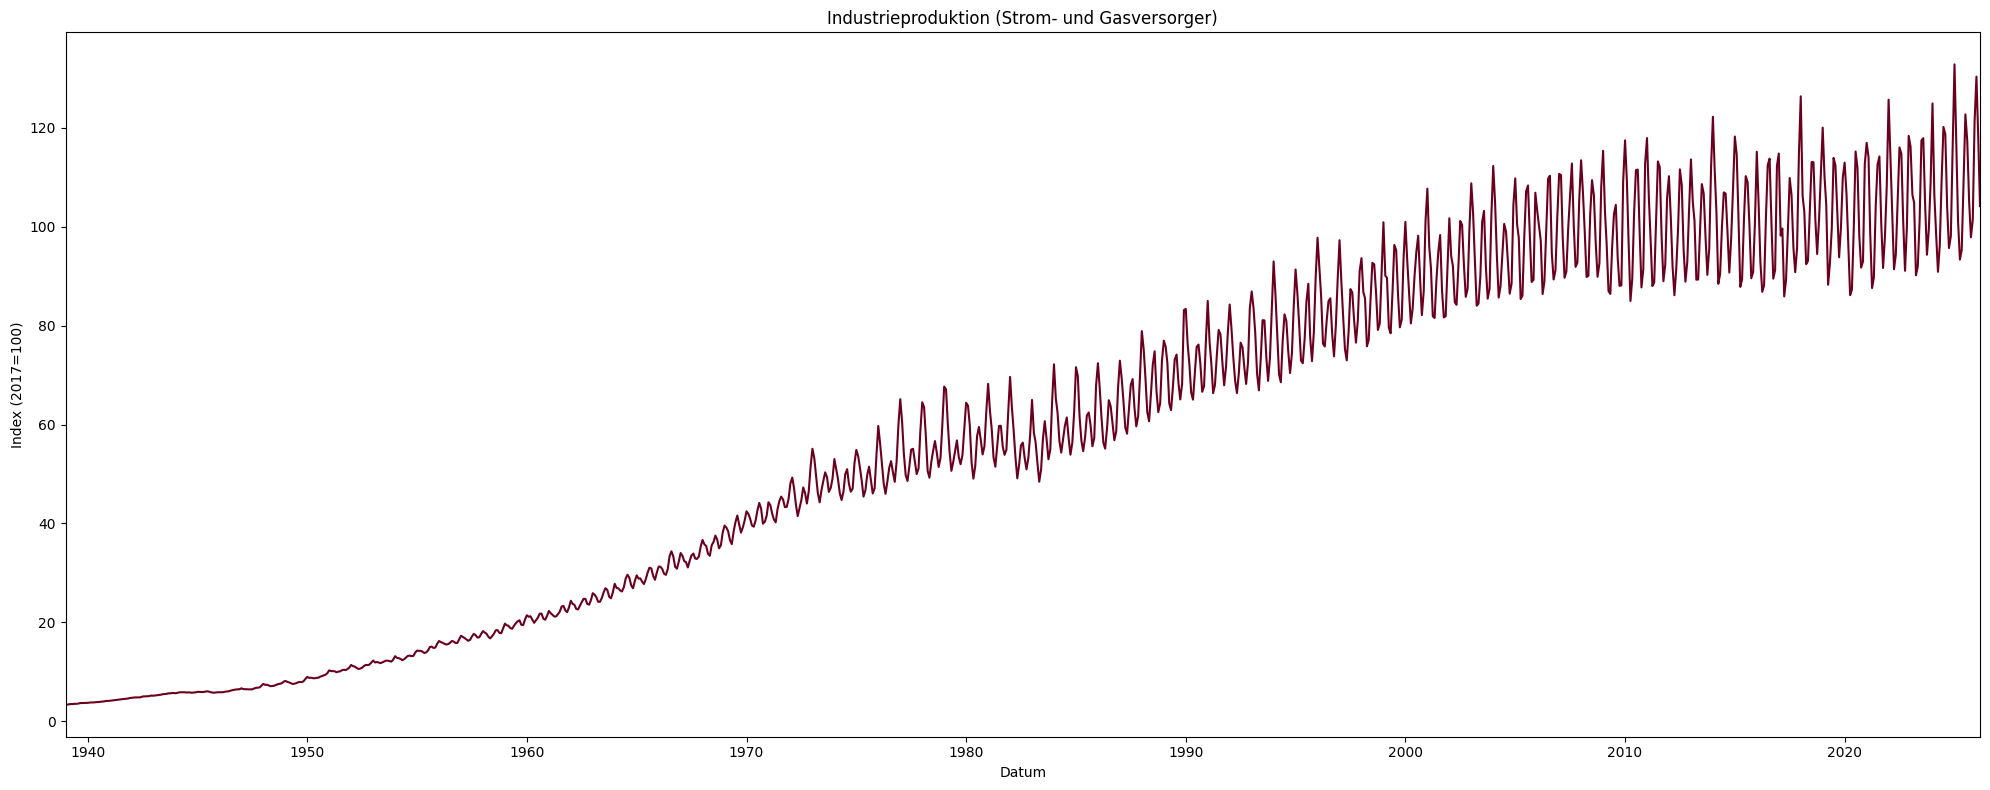

In [22]:
df = pd.read_csv("data.csv")
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.rename(columns={"observation_date": "date", "IPG2211A2N": "value"})
df = df.set_index("date").sort_index()
display(df)

plt.figure(figsize=(20, 8))

plt.plot(df["value"].sort_index(), color="#6B001E")

plt.title("Industrieproduktion (Strom- und Gasversorger)")
plt.xlabel("Datum")
plt.ylabel("Index (2017=100)")
plt.margins(x=0)
plt.tight_layout()
plt.show()

### Saisonalität

Hier ist es sinnvoll, die Saisonalität der Jahre und Jahrzehnte zu betrachten.

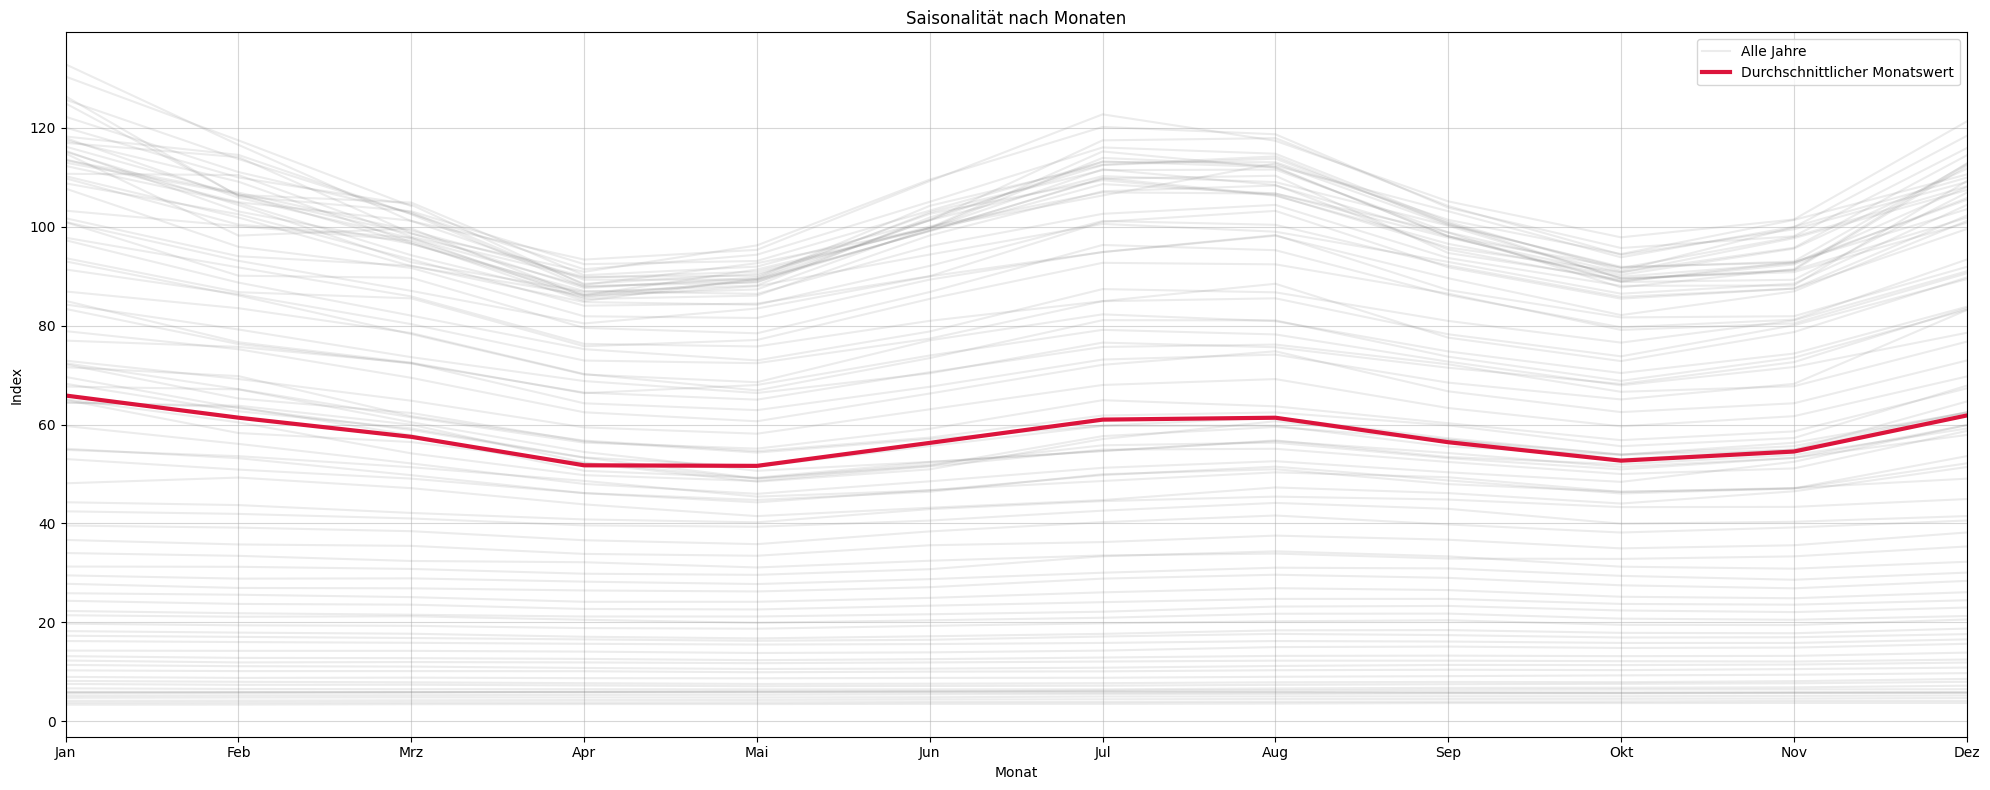

In [23]:
def analyse_seasonality(df: pd.DataFrame, col: str = "value", title: str = "", y: str = "Index") -> None:
    df = df.copy()
    df["month"] = df.index.month  # Fokus auf ein Jahr setzen

    # Der Mittelwert aller Monate über alle Jahre
    seasonal = df.groupby("month")[col].mean()

    _, ax = plt.subplots(figsize=(20, 8))

    # Produktion aller Jahre zur Veranschaulichung
    df["pivot_year"] = df.index.year
    pivot_data = df.pivot_table(index="month", columns="pivot_year", values=col)

    lines = ax.plot(pivot_data, color="gray", alpha=0.15)
    if lines:
        lines[0].set_label("Alle Jahre")

    seasonal.plot(ax=ax, color="crimson", linewidth=3, label="Durchschnittlicher Monatswert")

    ax.set(
        title=title,
        xlabel="Monat",
        ylabel=y,
        xticks=range(1, 13),
        xticklabels=["Jan", "Feb", "Mrz", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"],
    )
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


analyse_seasonality(df, col="value", title="Saisonalität nach Monaten")

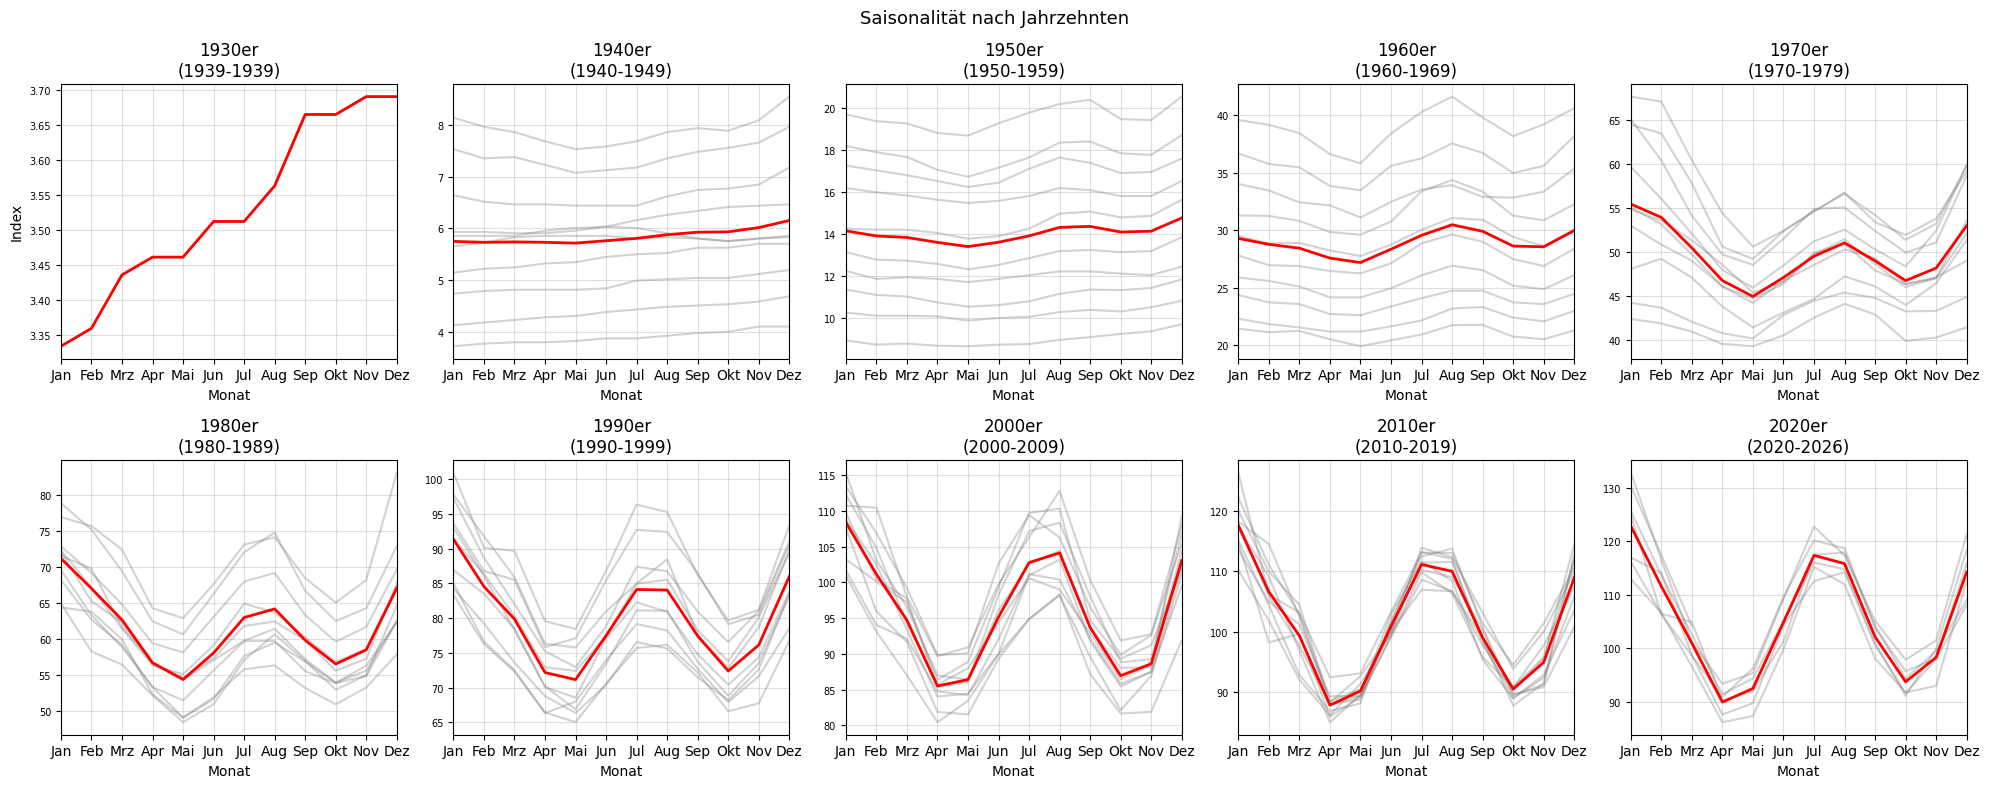

In [24]:
def analyse_seasonality_by_decade(df: pd.DataFrame, col: str = "value", title: str = "", y: str = "Index") -> None:
    df = df.copy()
    df["month"] = df.index.month
    df["year"] = df.index.year
    df["decade"] = (df["year"] // 10) * 10

    decades = sorted(df["decade"].unique())

    _, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=False)
    axes = axes.flatten()

    for ax, decade in zip(axes, decades):
        decade_df = df[df["decade"] == decade]
        pivot_data = decade_df.pivot_table(index="month", columns="year", values=col)
        seasonal = decade_df.groupby("month")[col].mean()

        lines = ax.plot(pivot_data, color="gray", alpha=0.35)
        if lines:
            lines[0].set_label("Einzelne Jahre")
        seasonal.plot(ax=ax, color="red", linewidth=2)

        ax.set(
            title=f"{decade}er\n({decade_df['year'].min()}-{decade_df['year'].max()})",
            xlabel="Monat",
            xticks=range(1, 13),
            xticklabels=["Jan", "Feb", "Mrz", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"],
        )
        ax.tick_params(axis="y", labelsize=7)
        ax.grid(axis="both", alpha=0.4)
        ax.margins(x=0)

    axes[0].set_ylabel(y)
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


analyse_seasonality_by_decade(df, col="value", title="Saisonalität nach Jahrzehnten")

<font color="orange">
Man sieht hier deutlich, dass wir eine multiplikative Saisonalität haben, da sich die saisonalen Ausschläge über die Jahrzehnte hinweg verstärken.
</font>

### Residuum

Wir verwenden hier zunächst STL zur Berechnung des Trends. Zur Ermittlung des Residuums berechnen wir die Saisonalität der Jahrzehnte, diesmal jedoch auf Basis der trendbereinigten Zeitreihe.

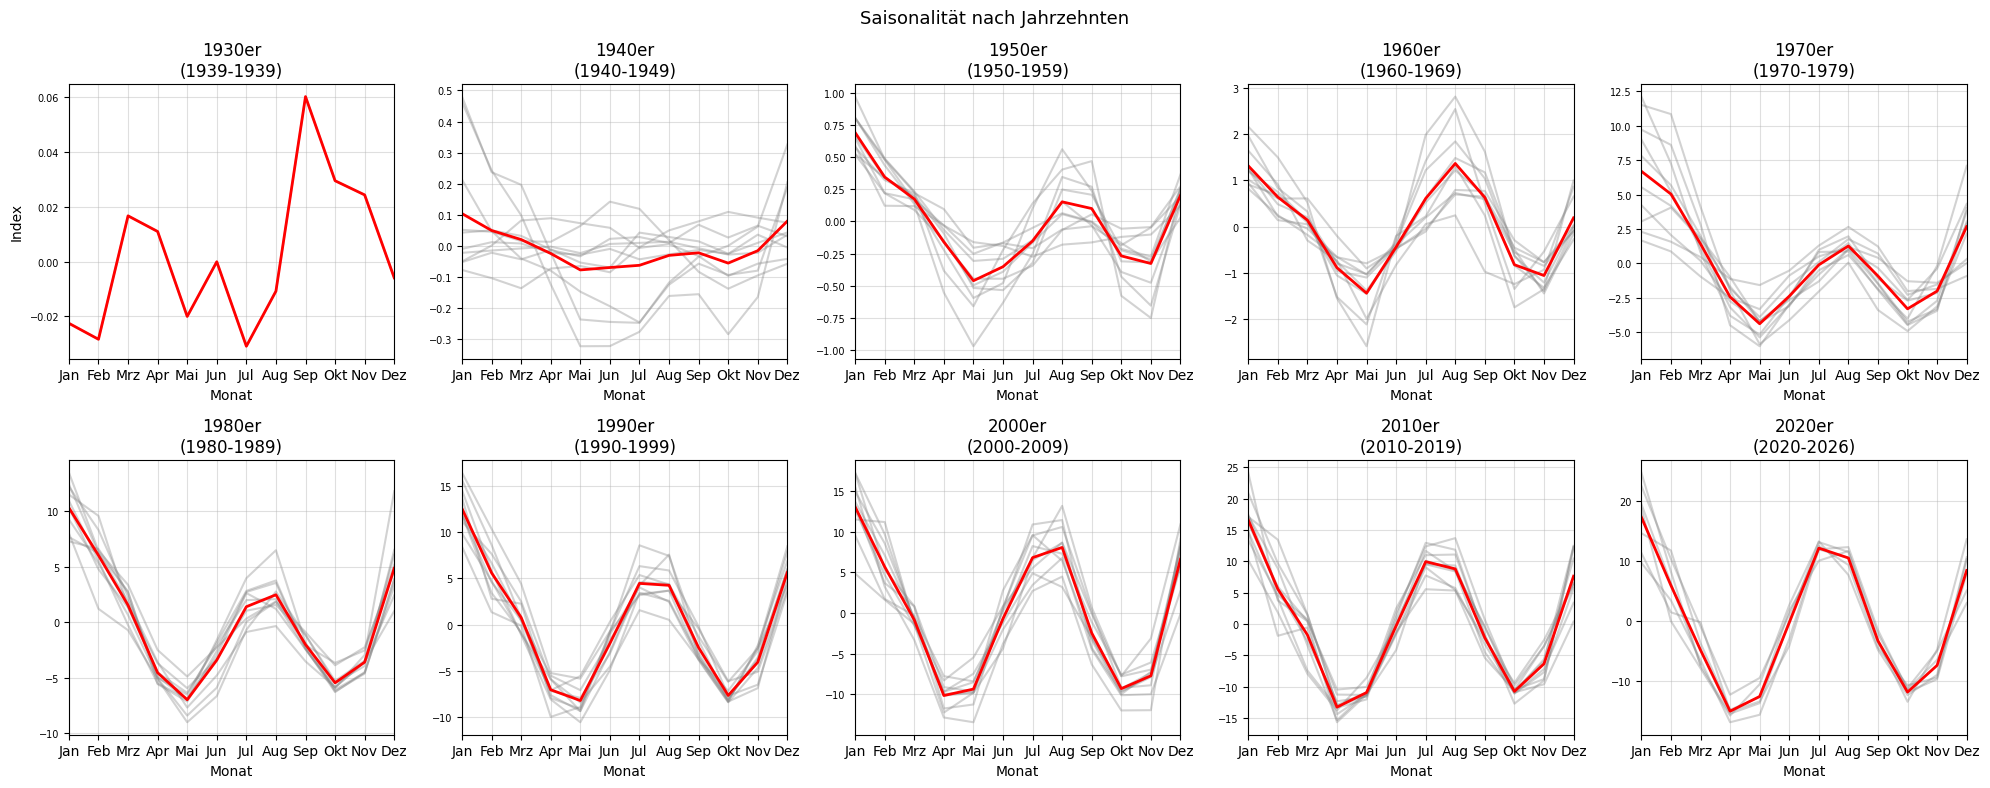

In [25]:
from statsmodels.tsa.seasonal import STL

decomposition = STL(df["value"], period=12, robust=True)
decomposition = decomposition.fit()

df["trend"] = decomposition.trend
df["value_detrended"] = df["value"] - df["trend"]

analyse_seasonality_by_decade(df, col="value_detrended", title="Saisonalität nach Jahrzehnten")

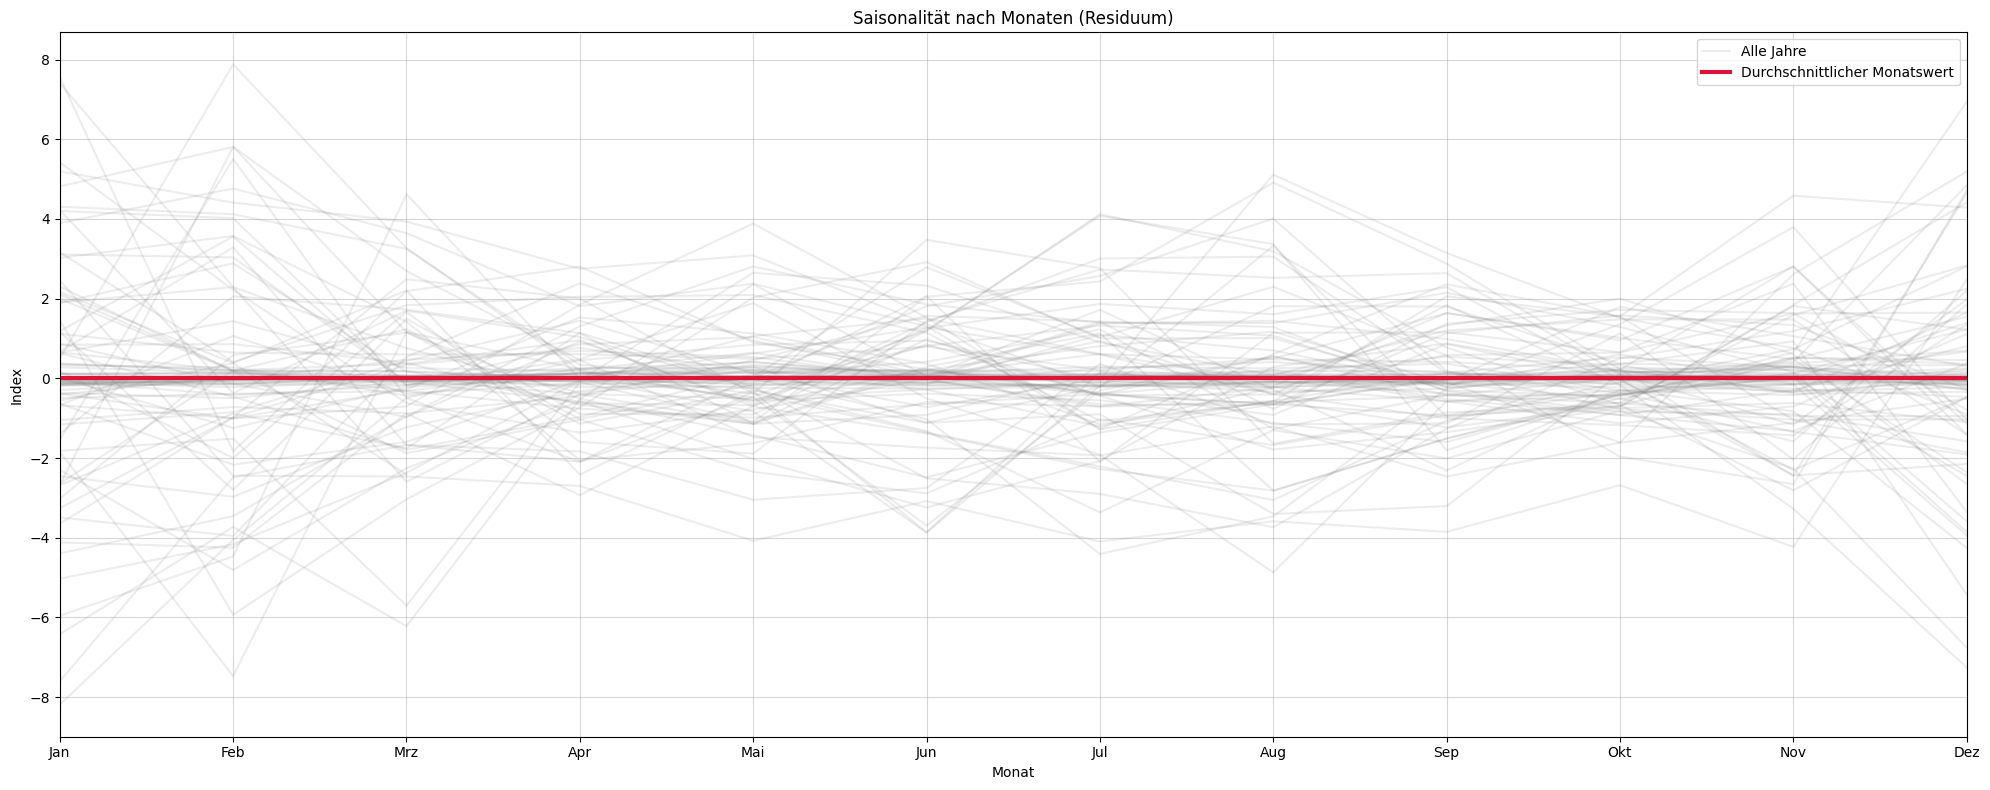

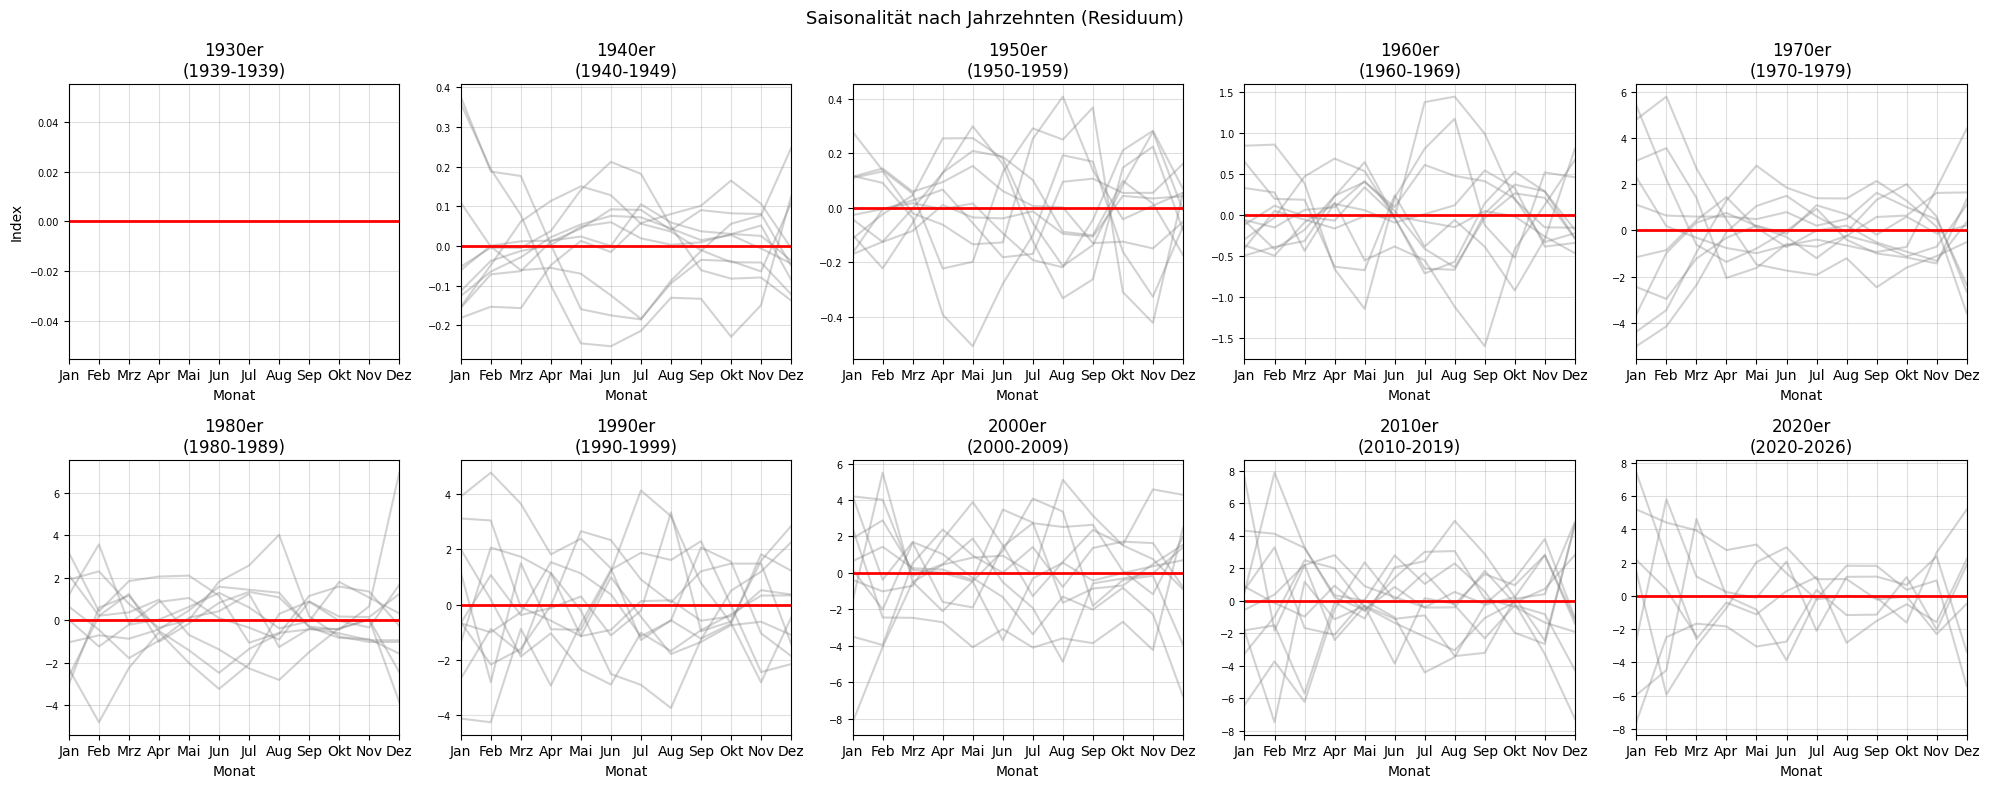

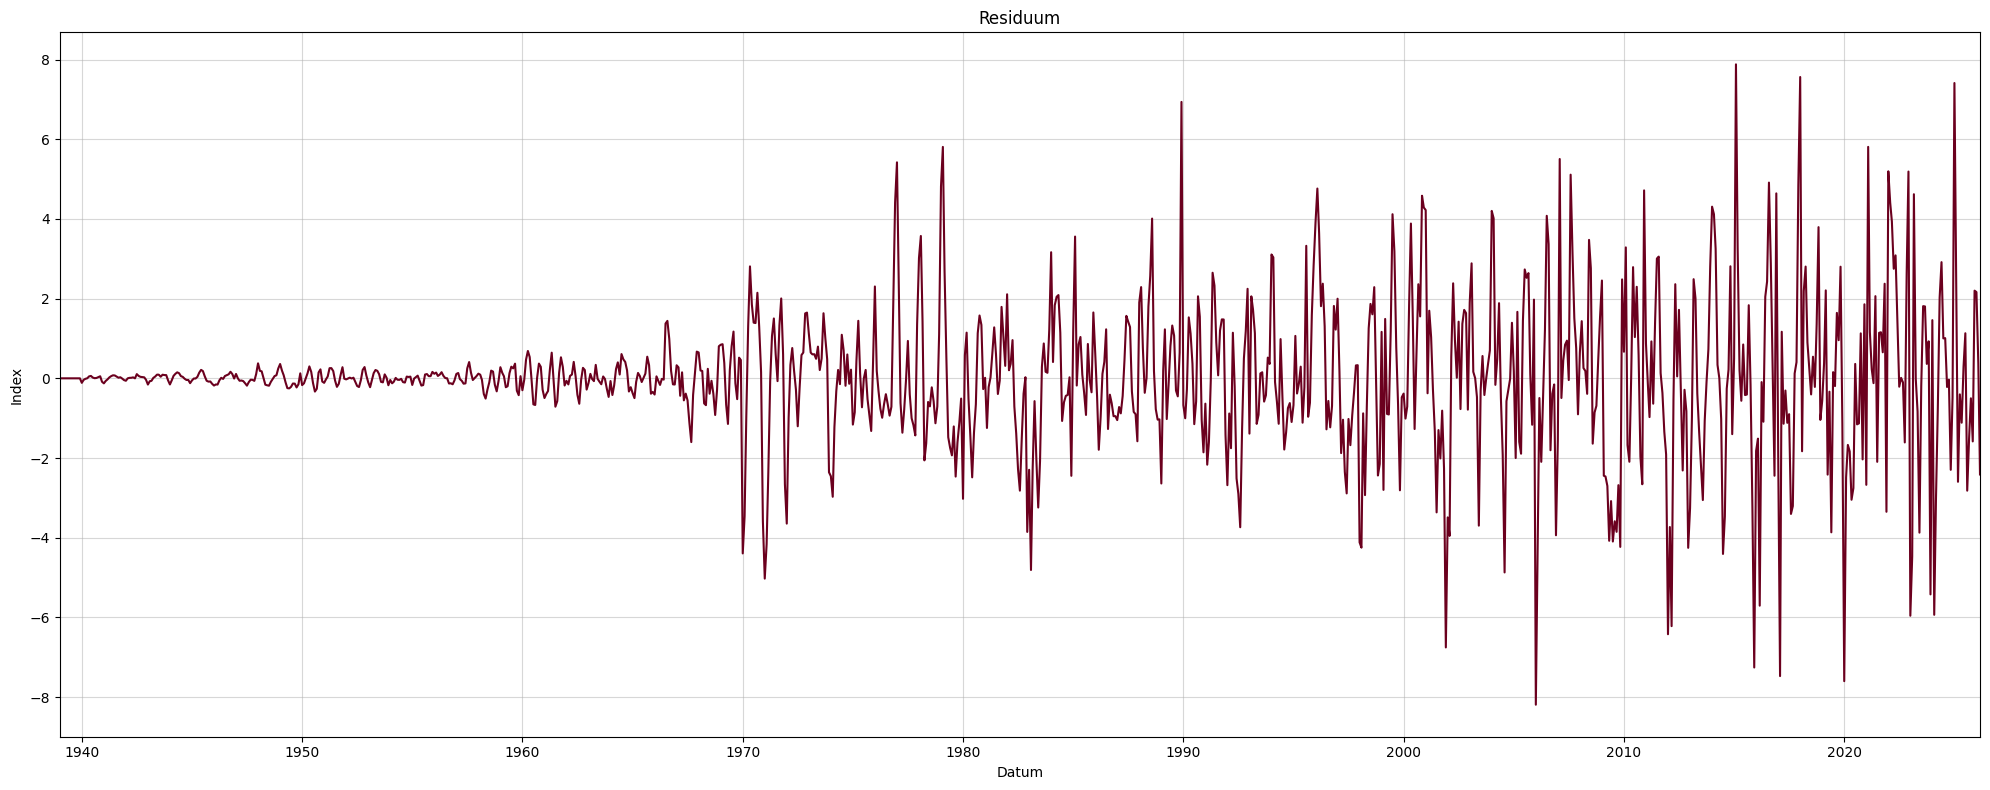

In [26]:
# Hilfsspalten
df["month"] = df.index.month
df["decade"] = (df.index.year // 10) * 10

# Saisonkomponente: Mittelwert je Dekade und Monat (auf der trendbereinigten Reihe)
df["seasonal_decade"] = df.groupby(["decade", "month"])["value_detrended"].transform("mean")

# Residuum
df["residuum"] = df["value_detrended"] - df["seasonal_decade"]

# Hilfsspalten entfernen
df = df.drop(columns=["month", "decade"])
analyse_seasonality(df, col="residuum", title="Saisonalität nach Monaten (Residuum)")
analyse_seasonality_by_decade(df, col="residuum", title="Saisonalität nach Jahrzehnten (Residuum)")

plt.figure(figsize=(20, 8))

plt.plot(df["residuum"].sort_index(), color="#6B001E")

plt.title("Residuum")
plt.xlabel("Datum")
plt.ylabel("Index")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.tight_layout()
plt.show()

<font color="orange">
Mittelwert der Saisonalitäten bei dem Residuum der Zeitreihe ist gleich 0, die Zeitreihe ist bereinigt.
</font>

# Transformation der Zeitreihe

Wir haben durch Recherche herausgefunden, dass sich für die Bereinigung multiplikativer Sasionalität der Logarithmus sehr gut eignet.

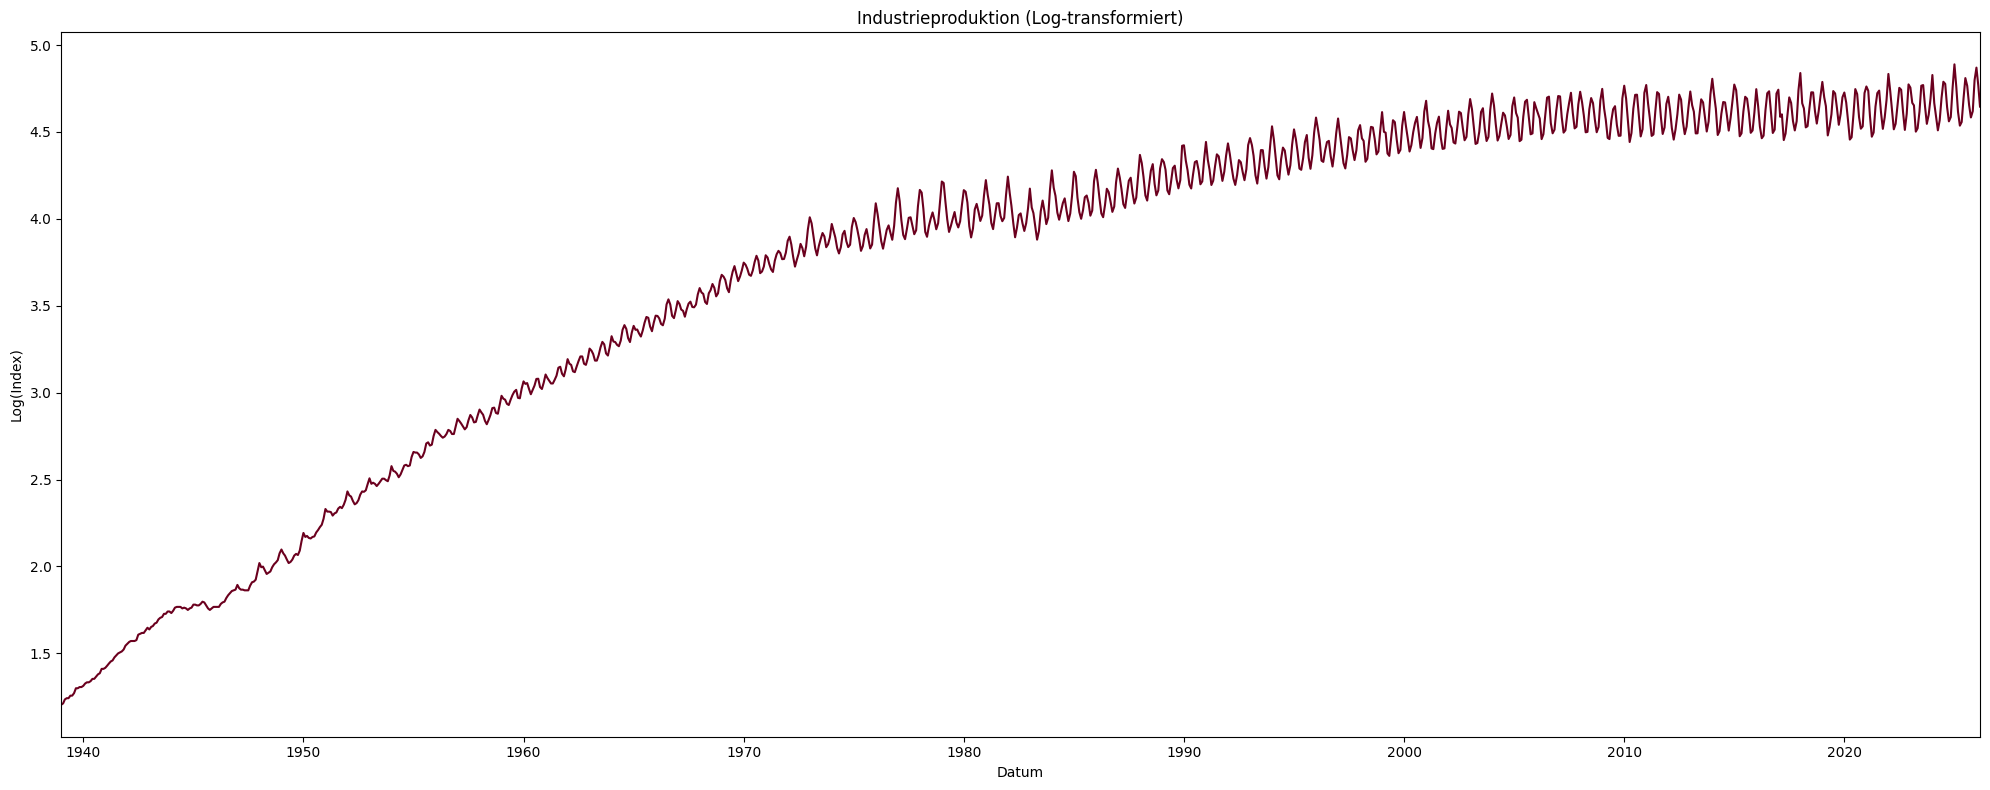

In [27]:
df["value_log"] = np.log(df["value"])

plt.figure(figsize=(20, 8))

plt.plot(df["value_log"].sort_index(), color="#6B001E")

plt.title("Industrieproduktion (Log-transformiert)")
plt.xlabel("Datum")
plt.ylabel("Log(Index)")
plt.margins(x=0)
plt.tight_layout()
plt.show()

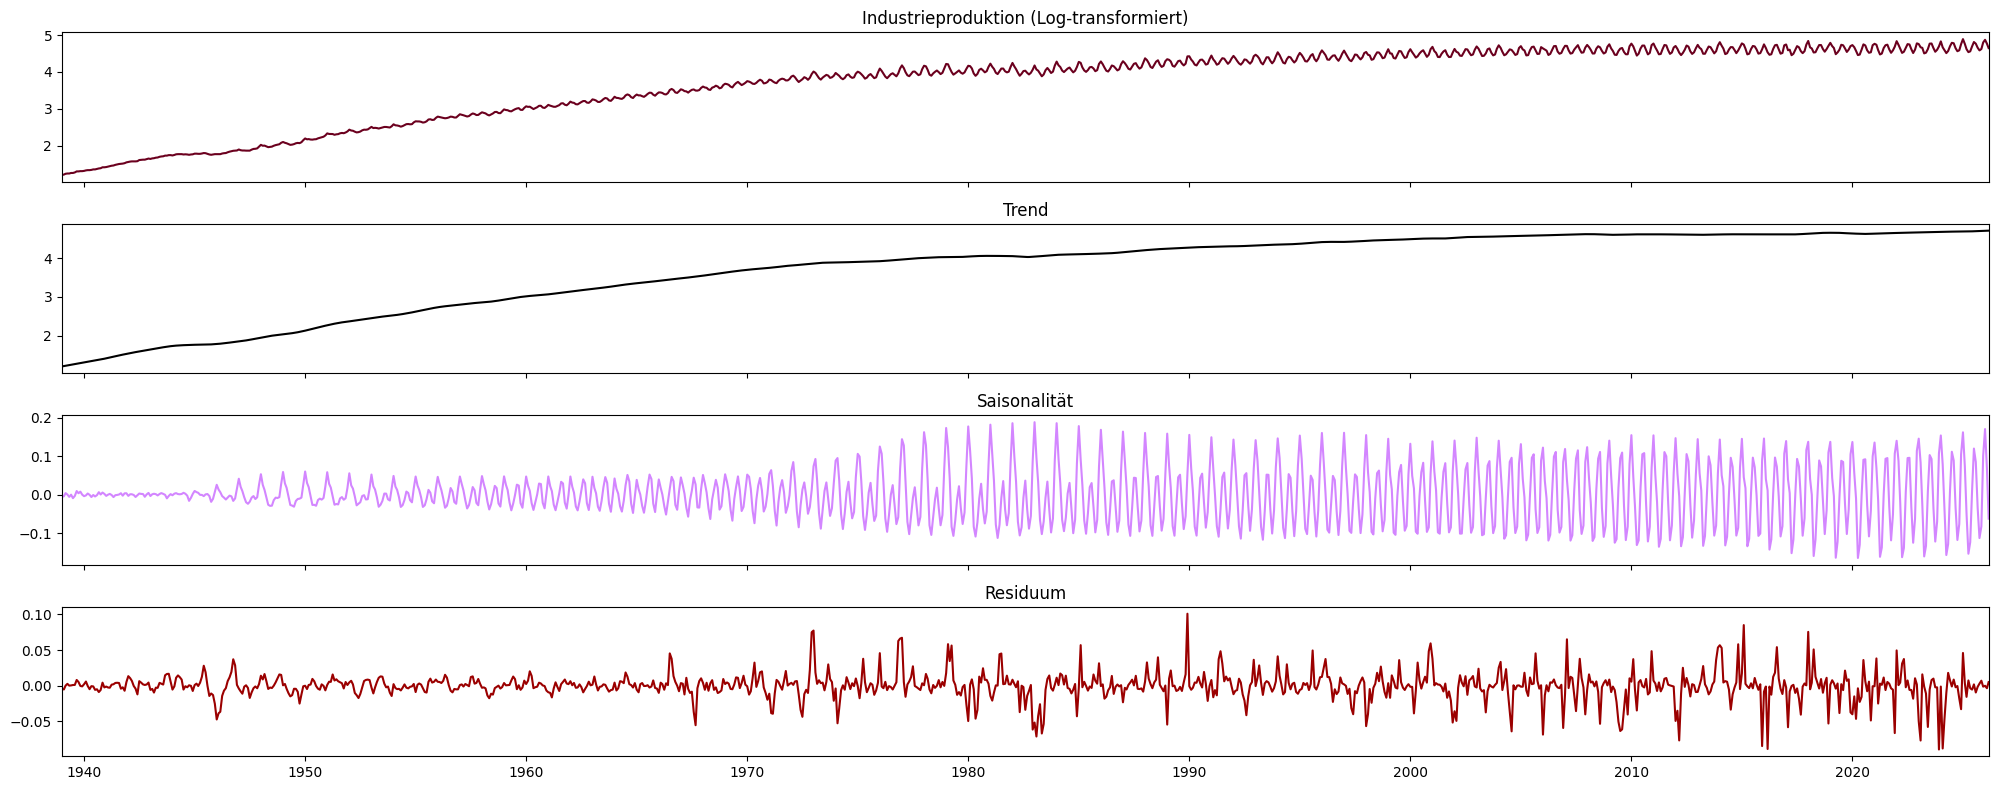

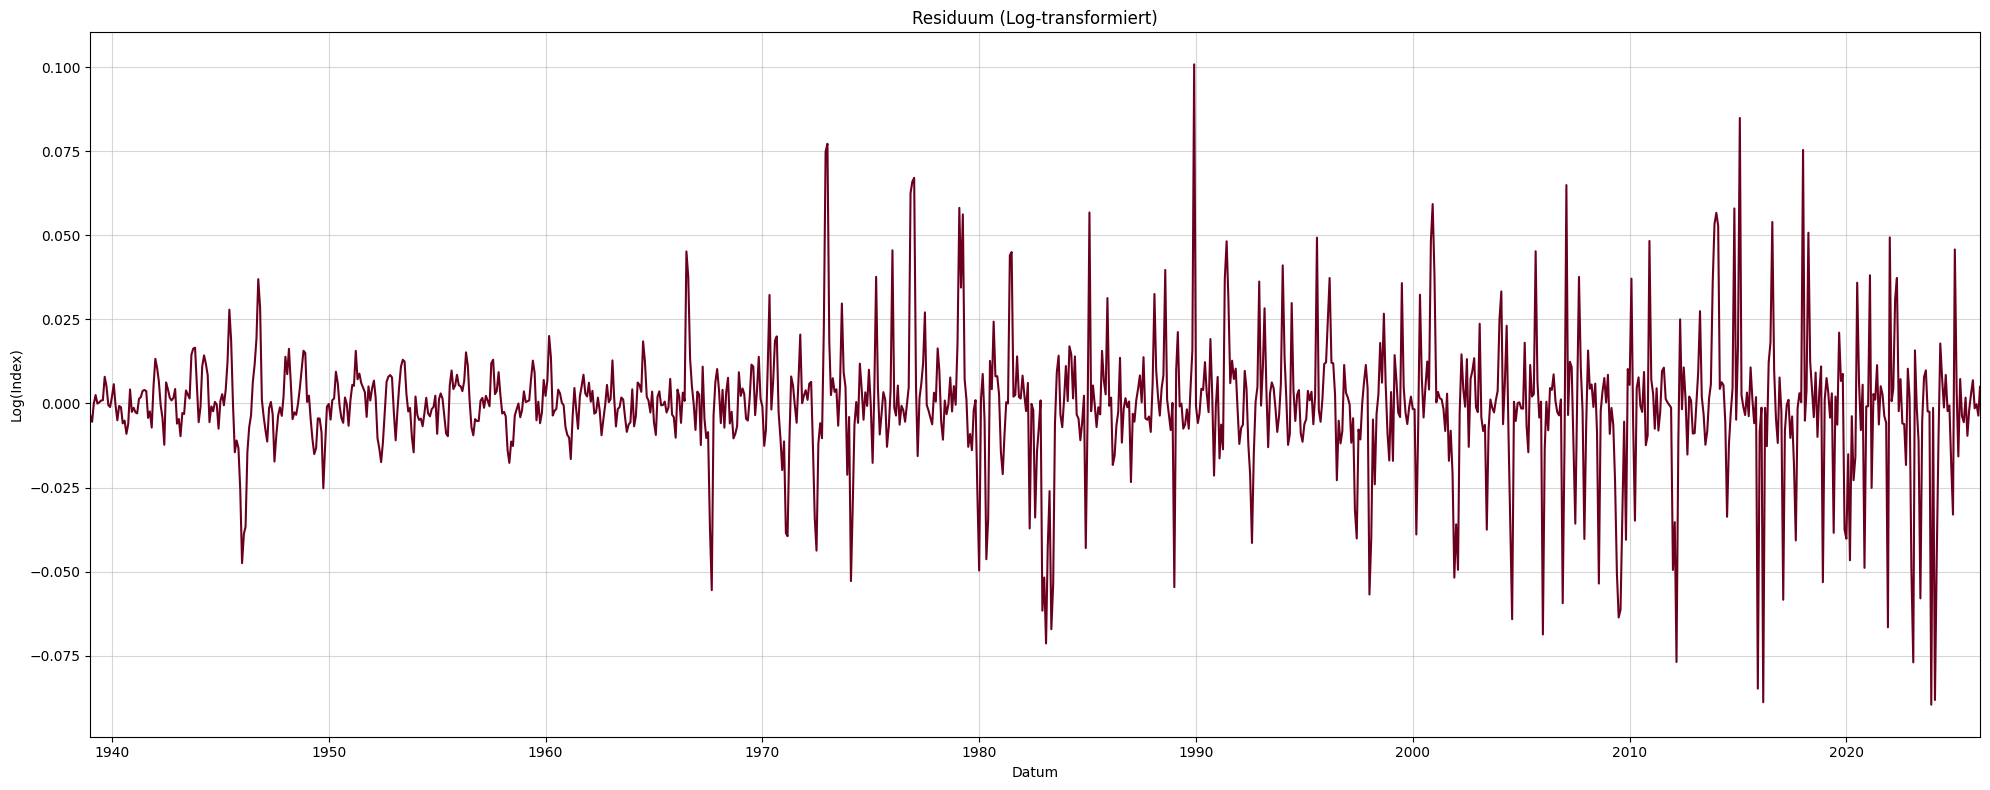

In [28]:
decomposition = STL(df["value_log"], period=12, robust=True)
decomposition = decomposition.fit()

# Zeitreihe, Trend, Saisonalität und Residuum
_, ax = plt.subplots(4, 1, figsize=(20, 8), sharex=True)

ax[0].plot(df["value_log"], color="#6B001E")
ax[0].set_title("Industrieproduktion (Log-transformiert)")
ax[1].plot(decomposition.trend, color="#000000FF")
ax[1].set_title("Trend")
ax[2].plot(decomposition.seasonal, color="#D386FF")
ax[2].set_title("Saisonalität")
ax[3].plot(decomposition.resid, color="#9B0000")
ax[3].set_title("Residuum")

plt.margins(x=0)
plt.tight_layout()
plt.show()

# Residuum der gesamten Zeitreihe
plt.figure(figsize=(20, 8))

plt.plot(decomposition.resid, color="#6B001E")

plt.title("Residuum (Log-transformiert)")
plt.xlabel("Datum")
plt.ylabel("Log(Index)")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.tight_layout()
plt.show()

df["log_trend"] = decomposition.trend
df["log_trendbereinigt"] = df["value_log"] - df["log_trend"]
df["log_saison"] = decomposition.seasonal
df["log_residuum"] = decomposition.resid

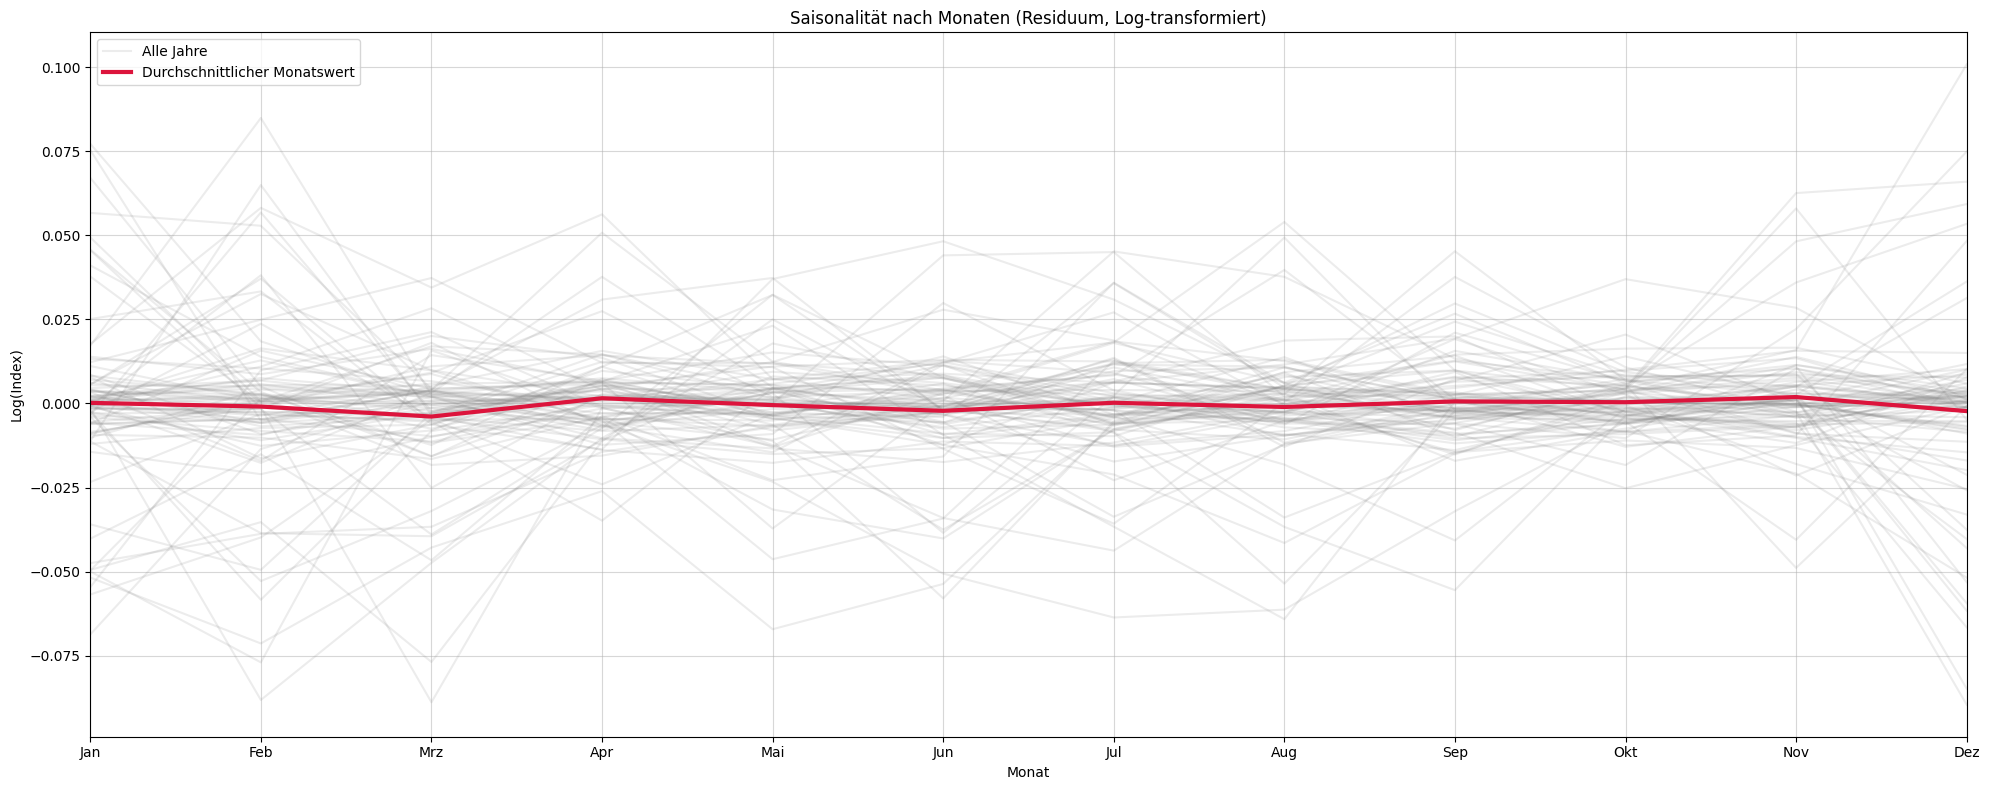

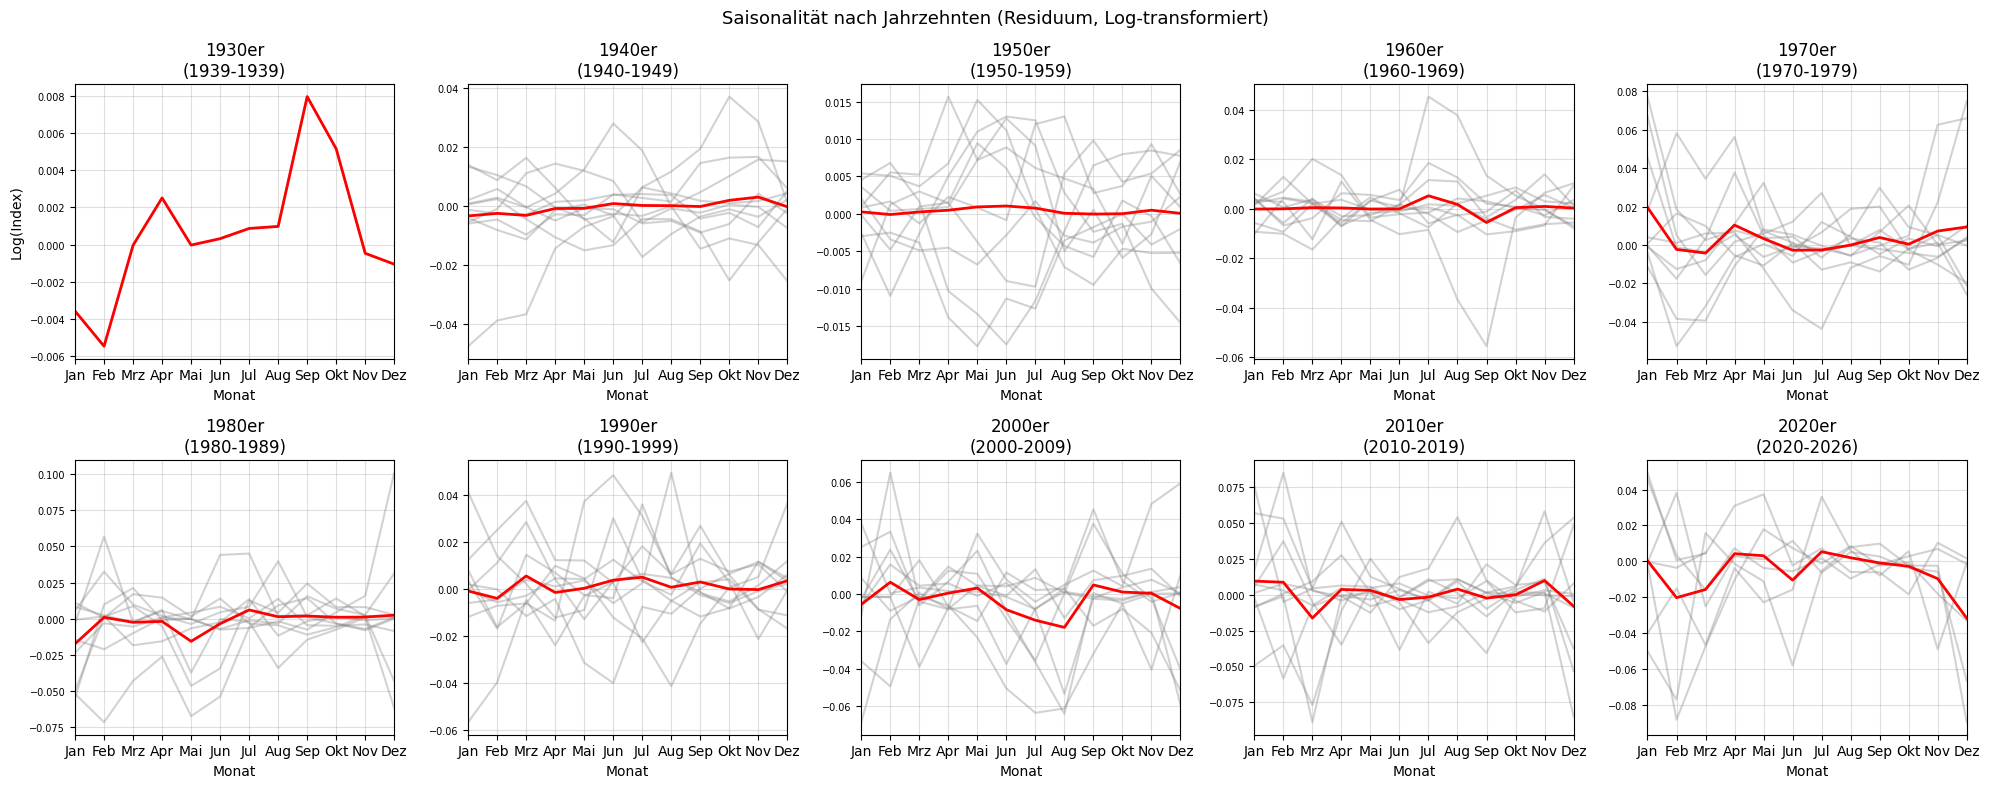

In [29]:
analyse_seasonality(
    df, col="log_residuum", title="Saisonalität nach Monaten (Residuum, Log-transformiert)", y="Log(Index)"
)
analyse_seasonality_by_decade(
    df, col="log_residuum", title="Saisonalität nach Jahrzehnten (Residuum, Log-transformiert)", y="Log(Index)"
)

<font color="orange">
Die Plots lassen erkennen, dass die Zeitreihe bereinigt ist. Die Saisonalitäten (Mittelwerte) liegen nahe 0, und das Residuum gleicht einem Rauschen.
</font>

### Autokorrelation

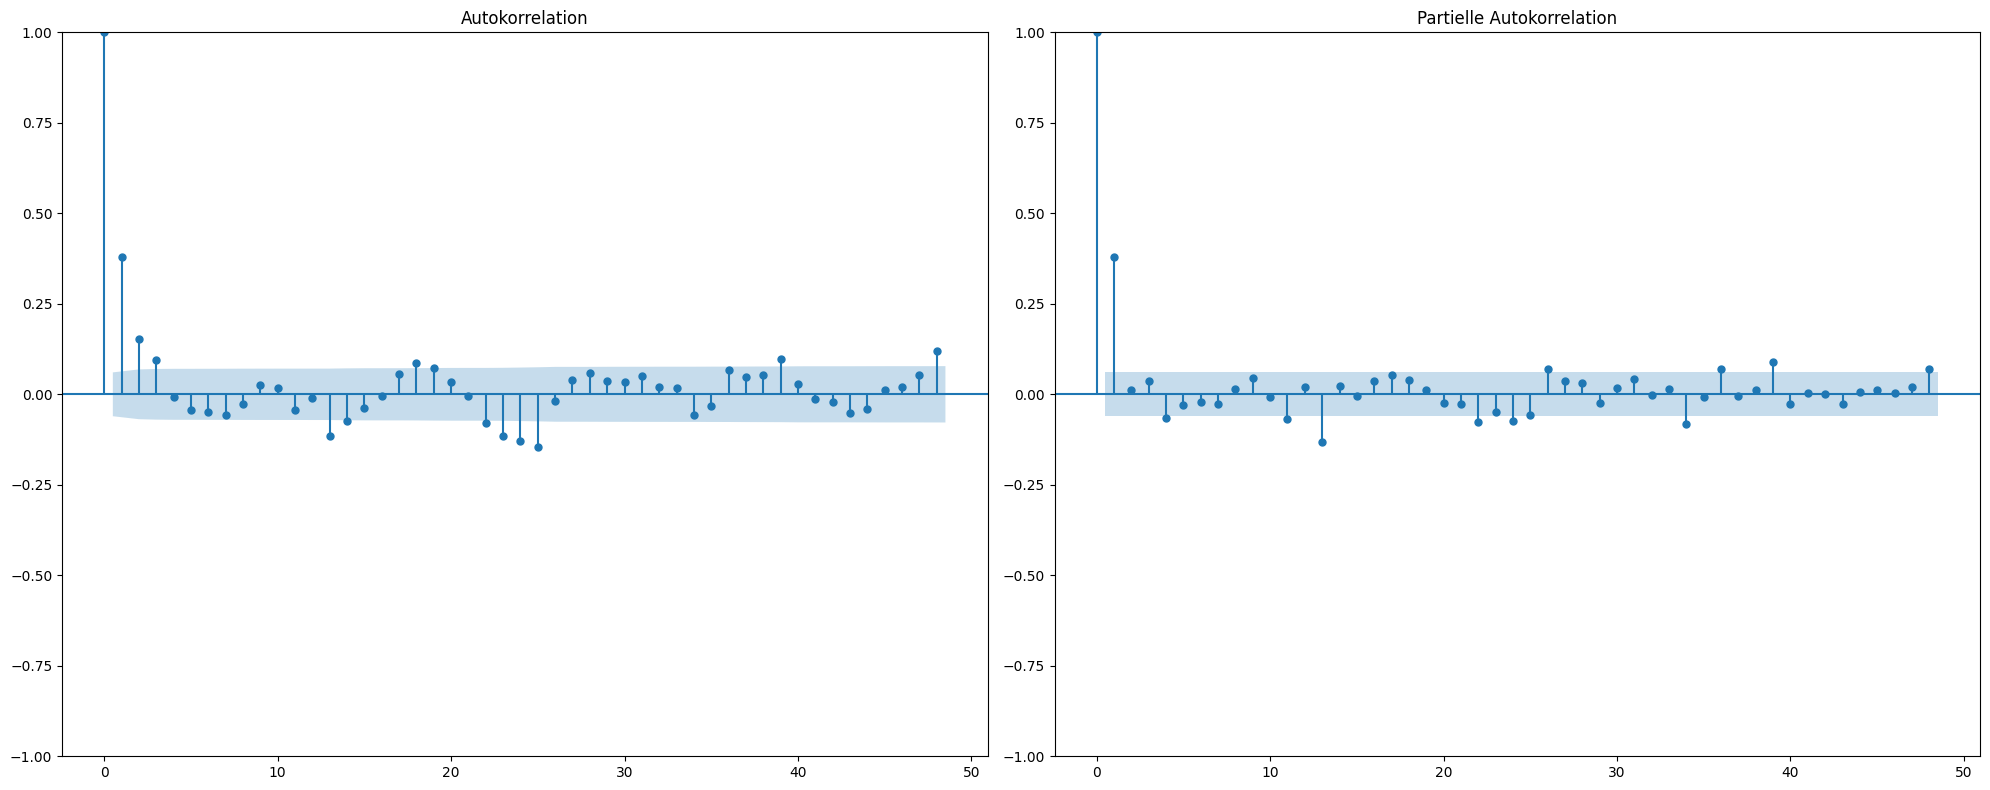

In [30]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_, ax = plt.subplots(1, 2, figsize=(20, 8))

# Autokorrelation
plot_acf(df["log_residuum"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

# Partielle Autokorrelation
plot_pacf(df["log_residuum"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

<font color="orange">
Die Autokorrelation-Werte schwanken relativ um 0 herum und zeigen keine Struktur, was darauf hindeutet, dass die Zeitreihe annähernd stationär ist.
</font>

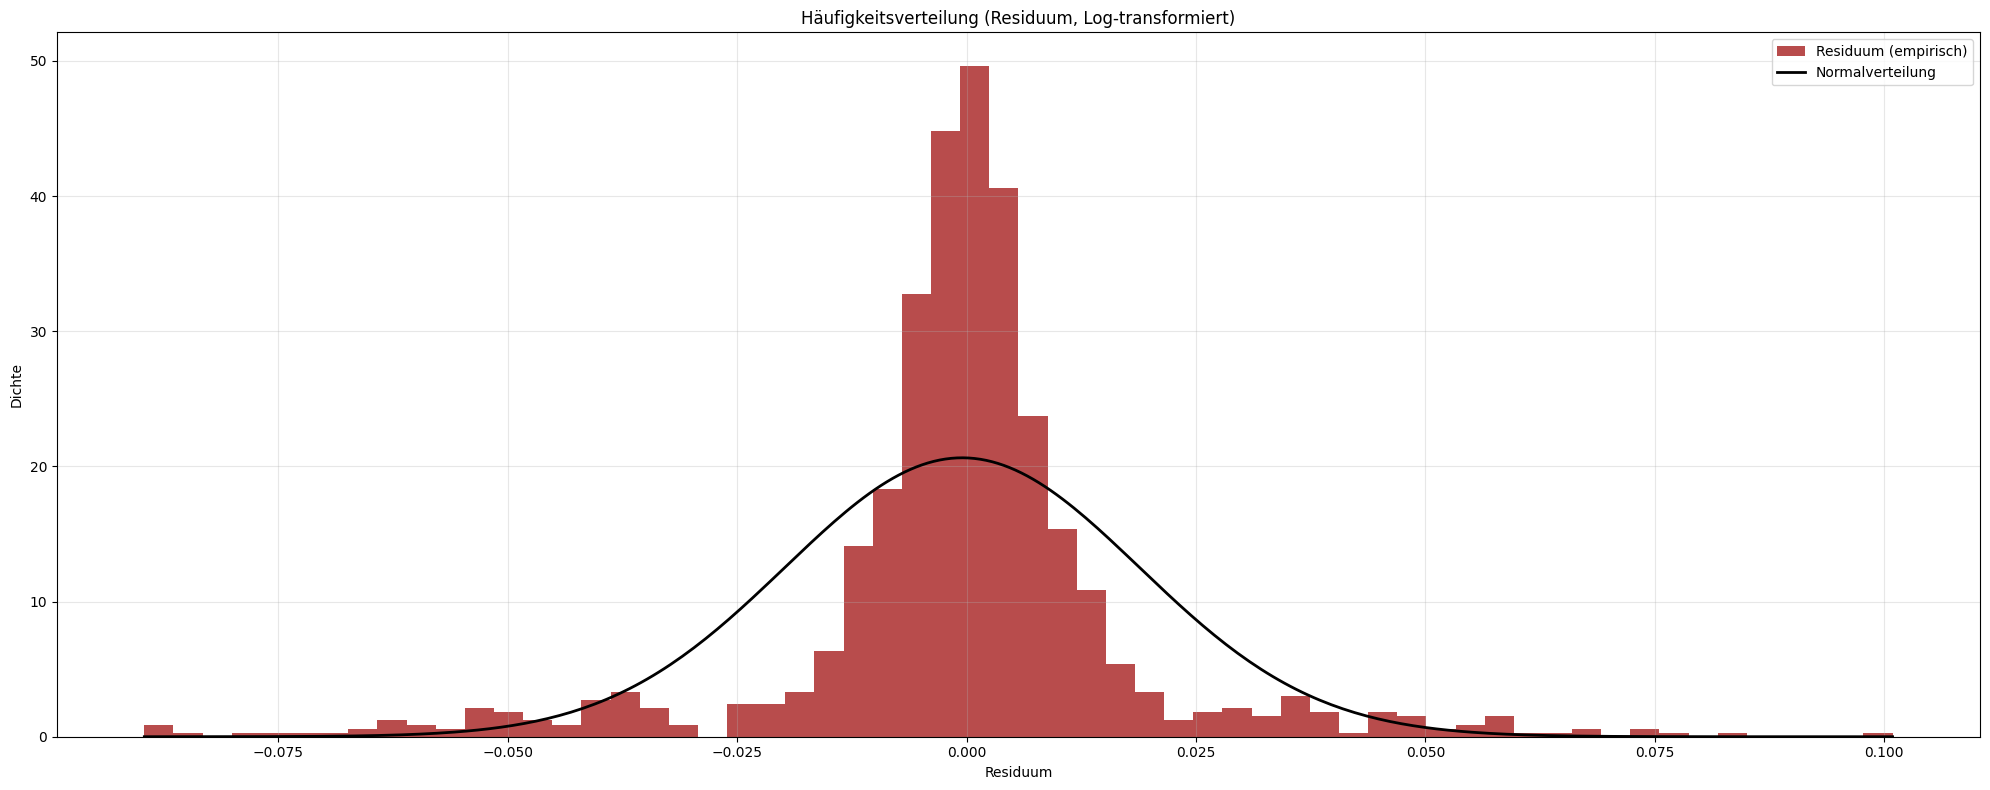

Mittelwert:          -0.000491
Standardabweichung:   0.019333
Schiefe:             -0.271467
Kurtosis:             5.439057


In [31]:
from scipy import stats

residuum = df["log_residuum"].dropna()
mu, std = stats.norm.fit(residuum)

_, ax = plt.subplots(figsize=(20, 8))

ax.hist(residuum, bins=60, density=True, color="#9B0000", alpha=0.7, label="Residuum (empirisch)")

x = np.linspace(residuum.min(), residuum.max(), 300)
ax.plot(x, stats.norm.pdf(x, mu, std), color="black", linewidth=2, label="Normalverteilung")

ax.set(
    title="Häufigkeitsverteilung (Residuum, Log-transformiert)",
    xlabel="Residuum",
    ylabel="Dichte",
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mittelwert:          {mu:.6f}")
print(f"Standardabweichung:   {std:.6f}")
print(f"Schiefe:             {residuum.skew():.6f}")
print(f"Kurtosis:             {residuum.kurtosis():.6f}")

<font color="orange">
Die Werte des Residuums sind (ungefähr) normalverteilt, daher eignet sich die Zeitreihe für ARIMA. Es gibt einige extreme Ausreißer, siehe Kurtosis.
</font>

# ARIMA

In [32]:
import warnings

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from statsmodels.tools.sm_exceptions import ValueWarning
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore", category=ValueWarning)

In [33]:
time_series = df["log_residuum"].dropna()

order = (1, 0, 2)
model = ARIMA(time_series, order=order, freq="MS")
model_fit = model.fit()

print(model_fit.summary())

# Vorhersage
pred = model_fit.predict()

                               SARIMAX Results                                
Dep. Variable:           log_residuum   No. Observations:                 1047
Model:                 ARIMA(1, 0, 2)   Log Likelihood                2727.354
Date:                Tue, 12 May 2026   AIC                          -5444.708
Time:                        18:05:17   BIC                          -5419.940
Sample:                    01-01-1939   HQIC                         -5435.316
                         - 03-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0005      0.001     -0.510      0.610      -0.002       0.001
ar.L1          0.5517      0.148      3.731      0.000       0.262       0.841
ma.L1         -0.1763      0.151     -1.164      0.2

<font color="orange">
AR: Hier haben wir 1 gewählt, da in der PACF der Lag 1 signifikant ist, und die weiteren nicht.<br><br>
Differencing: Da wir Saisonalität rausgerechnet haben (bzw. die Zeitreihe annähernd stationär ist), benötigen wir keine Differenzierung, daher 0.<br><br>
MA: Hier sind bei der ACF die Lags 1 und 2 signifikant, daher wird für MA 2 gewählt.
</font>

In [34]:
# Metriken
# Hier zu betrachten: MSE
print(f"MSE:    {mean_squared_error(time_series, pred):.7f}")
print(f"RMSE:   {root_mean_squared_error(time_series, pred):.7f}")
print(f"MAE:    {mean_absolute_error(time_series, pred):.7f}")
print(f"R²:     {r2_score(time_series, pred):.7f}")

MSE:    0.0003198
RMSE:   0.0178825
MAE:    0.0111193
R²:     0.1444445


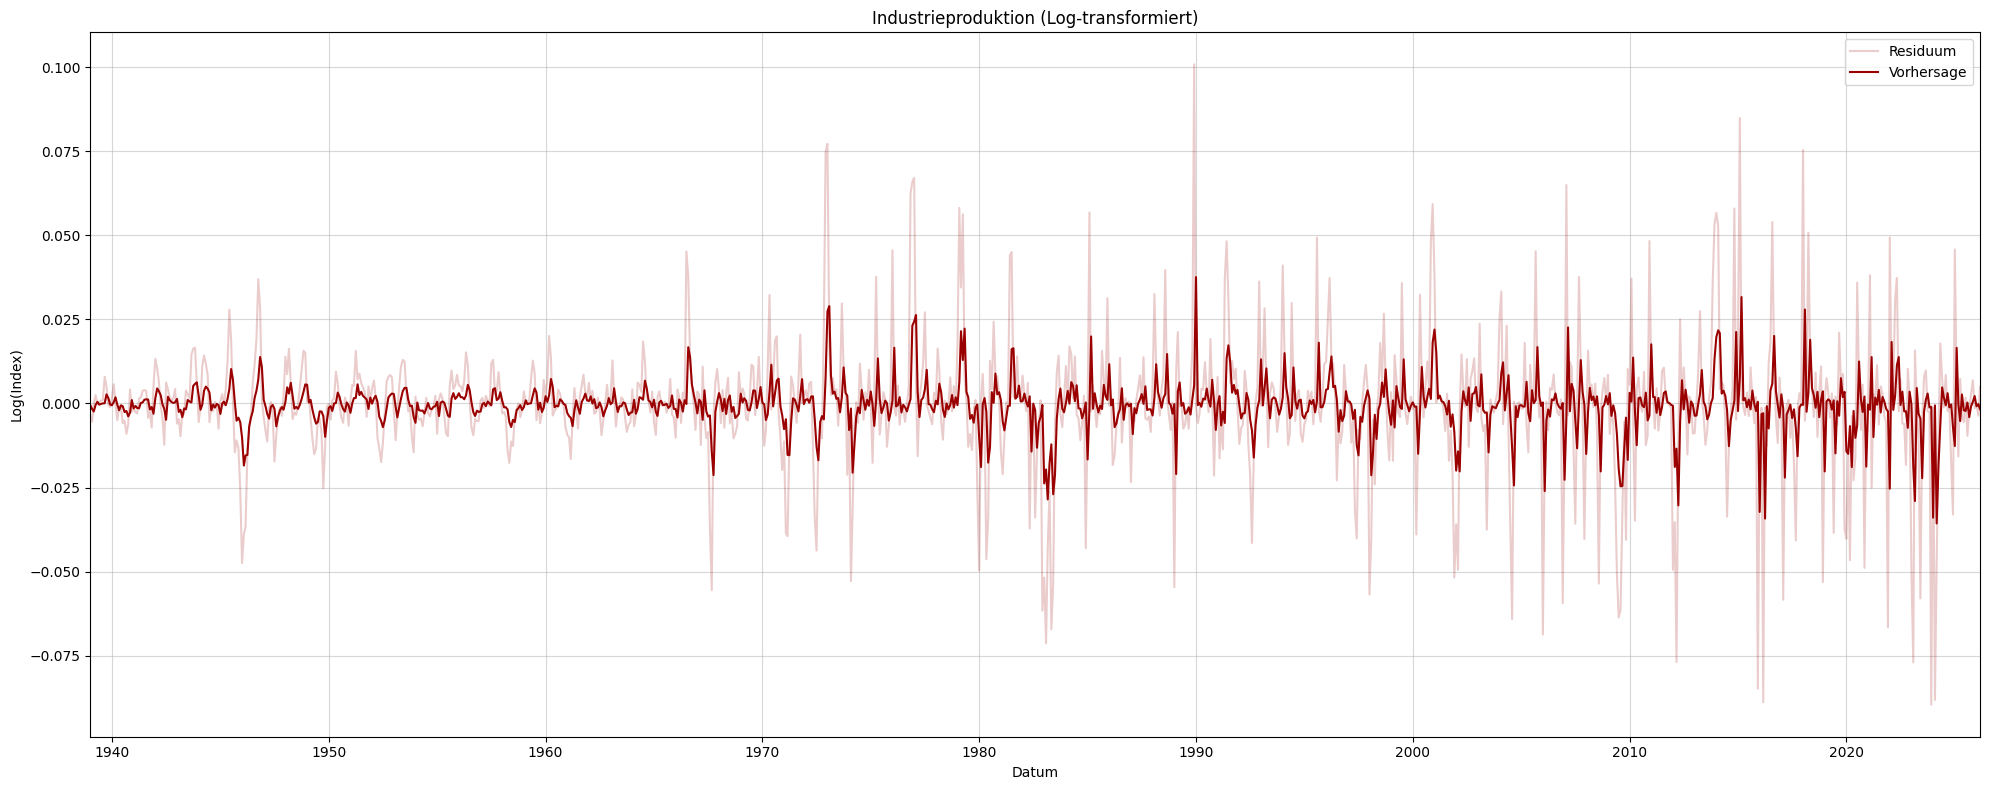

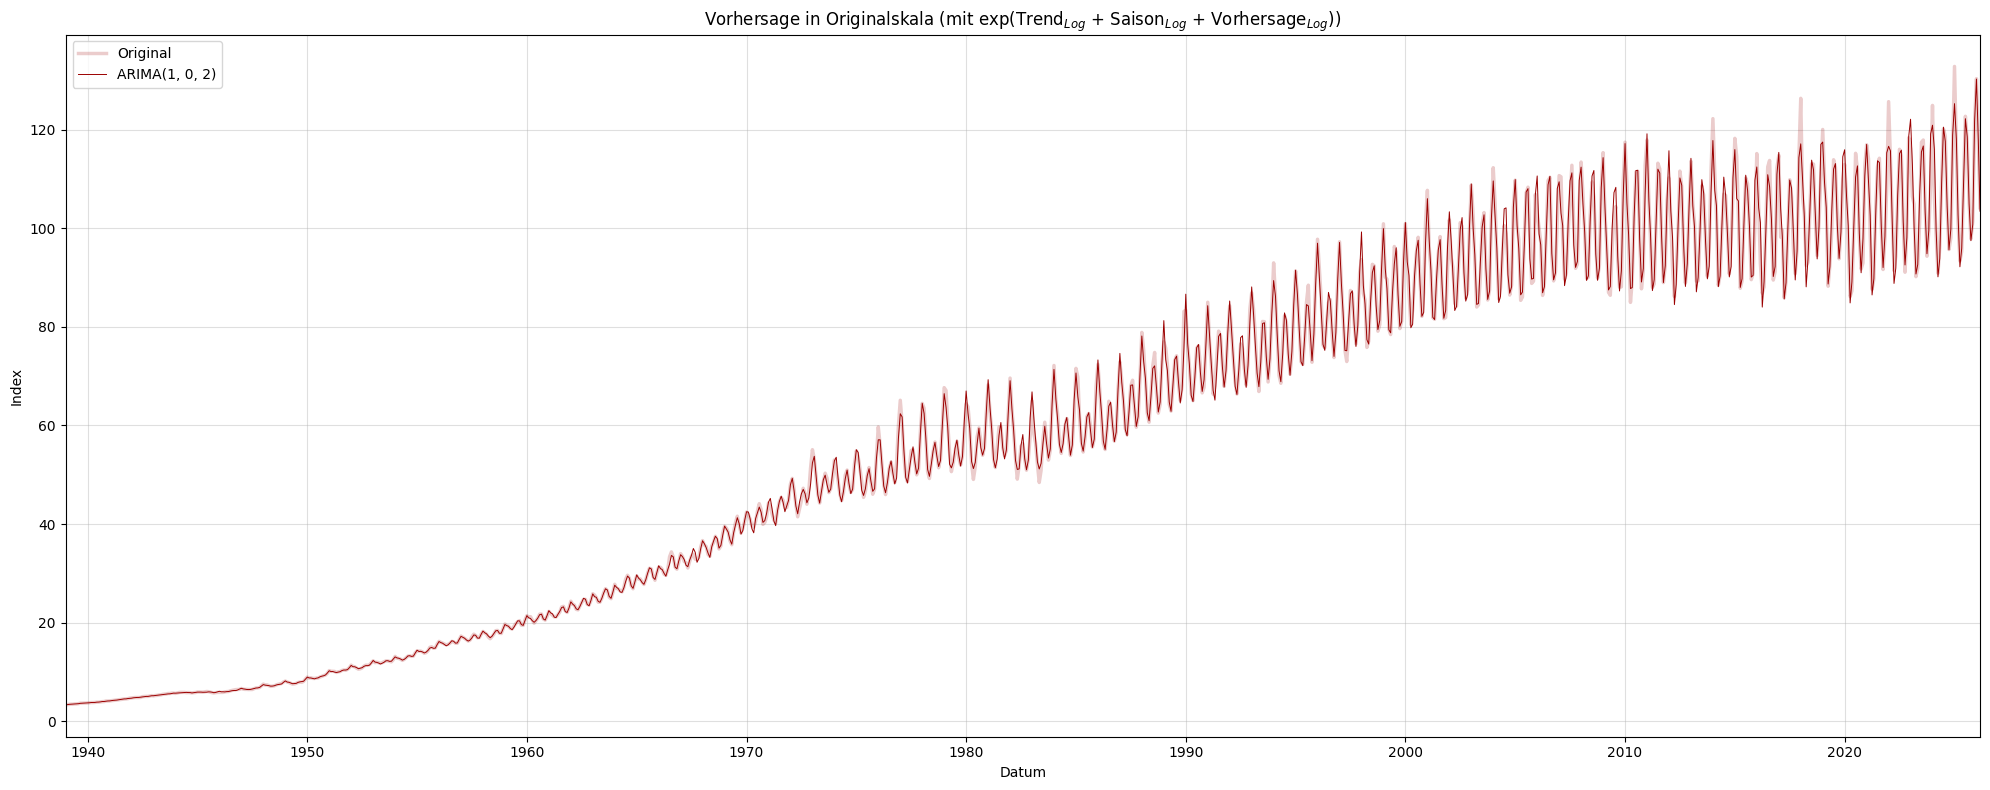

MSE:    2.5529391
RMSE:   1.5977919
MAE:    0.8128636
R²:     0.9980682


In [36]:
# Darstellung
plt.figure(figsize=(20, 8))

plt.plot(df.index, df["log_residuum"], color="#9B0000", alpha=0.2, label="Residuum")
plt.plot(df.index, pred, color="#9B0000", label="Vorhersage")

plt.title("Industrieproduktion (Log-transformiert)")
plt.xlabel("Datum")
plt.ylabel("Log(Index)")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

# Rücktransformation jeder Modellvorhersage in den Originalraum
df_plot = df.dropna(subset=["log_trend", "log_saison", "log_residuum"]).copy()
df_plot["original"] = np.exp(df_plot["log_trend"] + df_plot["log_saison"] + pred)

plt.figure(figsize=(20, 8))

plt.plot(df_plot.index, df_plot["value"], color="#9B0000", alpha=0.2, linewidth=2.5, label="Original")
plt.plot(df_plot.index, df_plot["original"], color="#9B0000", linewidth=0.7, label=f"ARIMA{order}")

plt.title(r"Vorhersage in Originalskala (mit exp(Trend$_{Log}$ + Saison$_{Log}$ + Vorhersage$_{Log}$))")
plt.xlabel("Datum")
plt.ylabel("Index")
plt.grid(alpha=0.4)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

# Metriken
print(f"MSE:    {mean_squared_error(df['value'], df_plot['original']):.7f}")
print(f"RMSE:   {root_mean_squared_error(df['value'], df_plot['original']):.7f}")
print(f"MAE:    {mean_absolute_error(df['value'], df_plot['original']):.7f}")
print(f"R²:     {r2_score(df['value'], df_plot['original']):.7f}")

<font color="orange">
Die Extremwerte (Varianz) werden auf den ersten Blick zwar nicht getroffen, bedenkt man jedoch die Skala um die es sich hier handelt, sind die vorhergesagten Werte sehr nah dran.

Transformiert man die Zeitreihe zur Originalskala, sind die relativen Abweichungen geringer. Die ausgegebene Evaluations-Metriken bestätigen dies.
</font>